# Cross-Variety Evaluation: RoBERTa-base

This notebook implements the full Cross-Variety Evaluation Matrix using RoBERTa-base for the Sentiment classification task.

The core research question is whether a model fine-tuned on one variety of English can transfer to another. Three separate models are trained — one per variety — using only that variety's training split. Each model is then evaluated on all three test splits, producing a 3×3 evaluation matrix of Macro-F1 scores. This directly measures the variety gap between inner-circle (en-UK, en-AU) and outer-circle (en-IN) English.

In [29]:
import os
import numpy as np
import pandas as pd
import evaluate

from datasets import Dataset, load_dataset
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    TrainingArguments,
    Trainer
)
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

Data Loading

The predefined train, validation, and test splits are loaded from the locally stored BESSTIE files. The test set remains strictly held out until final evaluation.


In [30]:
os.makedirs("../data/raw", exist_ok=True)

dataset = load_dataset("surrey-nlp/BESSTIE-CW-26")

train_df = dataset["train"].to_pandas()
val_df   = dataset["validation"].to_pandas()
test_df  = dataset["test"].to_pandas()

train_df.to_csv("../data/raw/besstie_train.csv", index=False)
val_df.to_csv("../data/raw/besstie_validation.csv", index=False)
test_df.to_csv("../data/raw/besstie_test.csv", index=False)

print("CSV files created successfully")

base_path = "../data/raw"
train_df = pd.read_csv(os.path.join(base_path, "besstie_train.csv"))
val_df   = pd.read_csv(os.path.join(base_path, "besstie_validation.csv"))
test_df  = pd.read_csv(os.path.join(base_path, "besstie_test.csv"))

print("Train shape:", train_df.shape)
print("Validation shape:", val_df.shape)
print("Test shape:", test_df.shape)

CSV files created successfully
Train shape: (3747, 5)
Validation shape: (313, 5)
Test shape: (2183, 5)


## Task Definition

We focus on the Sentiment classification task (Positive = 1, Negative = 0). The dataset is partitioned by the `variety` column so that each model is trained exclusively on text from one English variety, directly replicating a scenario where labelled data exists for one dialect but not others.

In [31]:
TEXT_COL  = "text"
LABEL_COL = "Sentiment"
VARIETIES = ["en-UK", "en-AU", "en-IN"]

# Partition by variety
train_by_variety = {v: train_df[train_df["variety"] == v].copy() for v in VARIETIES}
val_by_variety   = {v: val_df[val_df["variety"]   == v].copy() for v in VARIETIES}
test_by_variety  = {v: test_df[test_df["variety"]  == v].copy() for v in VARIETIES}

for v in VARIETIES:
    print(f"{v} — train: {len(train_by_variety[v])}, val: {len(val_by_variety[v])}, test: {len(test_by_variety[v])}")

en-UK — train: 1203, val: 101, test: 700
en-AU — train: 1145, val: 95, test: 667
en-IN — train: 1399, val: 117, test: 816


Tokenisation

RoBERTa uses subword tokenisation, which enables it to handle lexical variation more effectively than classical frequency-based methods. A shared tokeniser is used across all three variety-specific models to ensure fair comparison.


model_name = "roberta-base"
tokenizer  = AutoTokenizer.from_pretrained(model_name)

In [ ]:
model_name = "roberta-base"
tokenizer  = AutoTokenizer.from_pretrained(model_name)

def tokenize_function(examples):
    return tokenizer(
        examples["text"],
        truncation=True,
        padding="max_length",
        max_length=128
    )

def prepare_dataset(df):
    """Convert a variety-specific DataFrame into a tokenised HuggingFace Dataset."""
    data = df[[TEXT_COL, LABEL_COL]].copy()
    data.columns = ["text", "label"]
    data["label"] = data["label"].astype(int)
    ds = Dataset.from_pandas(data, preserve_index=False)
    ds = ds.map(tokenize_function, batched=True)
    ds = ds.remove_columns(["text"])
    ds.set_format("torch")
    return ds

print("Tokeniser loaded:", model_name)

## Evaluation Metrics

Macro-F1 is used as the primary metric to ensure balanced evaluation across both classes.

In [34]:
accuracy_metric  = evaluate.load("accuracy")
f1_metric        = evaluate.load("f1")
precision_metric = evaluate.load("precision")
recall_metric    = evaluate.load("recall")

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    predictions = np.argmax(logits, axis=-1)

    accuracy  = accuracy_metric.compute(
        predictions=predictions,
        references=labels
    )["accuracy"]

    macro_f1  = f1_metric.compute(
        predictions=predictions,
        references=labels,
        average="macro"
    )["f1"]

    precision = precision_metric.compute(
        predictions=predictions,
        references=labels,
        average="macro",
        zero_division=0
    )["precision"]

    recall = recall_metric.compute(
        predictions=predictions,
        references=labels,
        average="macro",
        zero_division=0
    )["recall"]

    return {
        "accuracy":  accuracy,
        "macro_f1":  macro_f1,
        "precision": precision,
        "recall":    recall
    }

Training Arguments¶

The same hyperparameter configuration used in the RoBERTa baseline notebook is applied here for all three variety-specific models. This ensures any performance differences are due to training variety, not model configuration.


In [35]:
os.makedirs("../results/tables", exist_ok=True)
os.makedirs("../results/checkpoints", exist_ok=True)

def get_training_args(variety_tag):
    return TrainingArguments(
        output_dir=f"../results/checkpoints/roberta_crossvariety_{variety_tag}",
        eval_strategy="epoch",
        save_strategy="epoch",
        logging_strategy="epoch",
        learning_rate=2e-5,
        per_device_train_batch_size=8,
        per_device_eval_batch_size=8,
        num_train_epochs=2,
        weight_decay=0.01,
        load_best_model_at_end=True,
        metric_for_best_model="macro_f1",
        greater_is_better=True,
        save_total_limit=1,
        report_to="none"
    )

## Cross-Variety Training and Evaluation

Three separate RoBERTa-base models are fine-tuned, one per variety. For each training variety, the model is validated on that same variety's validation split to guide model selection. After training, each model is evaluated on all three test splits to populate the 3×3 evaluation matrix. Trained models are stored in a dictionary so they can be reused later without retraining.

In [36]:
# --- Tokenisation ---
model_name = "roberta-base"
tokenizer  = AutoTokenizer.from_pretrained(model_name)

def tokenize_function(examples):
    return tokenizer(
        examples["text"],
        truncation=True,
        padding="max_length",
        max_length=128
    )

def prepare_dataset(df):
    data = df[[TEXT_COL, LABEL_COL]].copy()
    data.columns = ["text", "label"]
    data["label"] = data["label"].astype(int)
    ds = Dataset.from_pandas(data, preserve_index=False)
    ds = ds.map(tokenize_function, batched=True)
    ds = ds.remove_columns(["text"])
    ds.set_format("torch")
    return ds

print("Tokeniser loaded:", model_name)

# --- Training Loop ---
results_matrix = {v: {} for v in VARIETIES}
trained_models = {}
all_rows = []

for train_variety in VARIETIES:
    print(f"\n{'='*60}")
    print(f"Training on: {train_variety}")
    print(f"{'='*60}")

    tokenized_train = prepare_dataset(train_by_variety[train_variety])
    tokenized_val   = prepare_dataset(val_by_variety[train_variety])

    model = AutoModelForSequenceClassification.from_pretrained(
        model_name,
        num_labels=2
    )
    model.config.problem_type = "single_label_classification"

    trainer = Trainer(
        model=model,
        args=get_training_args(train_variety.replace("-", "")),
        train_dataset=tokenized_train,
        eval_dataset=tokenized_val,
        compute_metrics=compute_metrics
    )

    trainer.train()
    trained_models[train_variety] = trainer

    for test_variety in VARIETIES:
        tokenized_test = prepare_dataset(test_by_variety[test_variety])
        test_results   = trainer.evaluate(tokenized_test)

        macro_f1 = test_results["eval_macro_f1"]
        results_matrix[train_variety][test_variety] = macro_f1

        all_rows.append({
            "train_variety": train_variety,
            "test_variety":  test_variety,
            "macro_f1":      round(macro_f1, 4),
            "precision":     round(test_results["eval_precision"], 4),
            "recall":        round(test_results["eval_recall"], 4),
            "accuracy":      round(test_results["eval_accuracy"], 4)
        })

        print(f"  Trained on {train_variety} -> Tested on {test_variety}: "
              f"Macro-F1 = {macro_f1:.4f}")

results_df = pd.DataFrame(all_rows)
results_path = "../results/tables/cross_variety_results.csv"
results_df.to_csv(results_path, index=False)
print(f"\nSaved results to: {results_path}")
results_df

Tokeniser loaded: roberta-base

Training on: en-UK


Loading weights: 100%|██████████| 197/197 [00:00<00:00, 13734.22it/s]
[transformers] RobertaForSequenceClassification LOAD REPORT from: roberta-base
Key                        | Status     | 
---------------------------+------------+-
lm_head.dense.weight       | UNEXPECTED | 
lm_head.layer_norm.bias    | UNEXPECTED | 
lm_head.layer_norm.weight  | UNEXPECTED | 
lm_head.dense.bias         | UNEXPECTED | 
lm_head.bias               | UNEXPECTED | 
classifier.out_proj.weight | MISSING    | 
classifier.dense.bias      | MISSING    | 
classifier.out_proj.bias   | MISSING    | 
classifier.dense.weight    | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch,Training Loss,Validation Loss,Accuracy,Macro F1,Precision,Recall
1,0.350556,0.197588,0.960396,0.960205,0.959316,0.961858
2,0.155700,0.188530,0.960396,0.960205,0.959316,0.961858


Map: 100%|██████████| 700/700 [00:00<00:00, 24400.69 examples/s]


Training Loss,Validation Loss,Epoch,Accuracy,Macro F1,Precision,Recall
0.155700,0.265888,2,0.938571,0.938543,0.938457,0.938725


...

  Trained on en-IN -> Tested on en-AU: Macro-F1 = 0.8858


Map: 100%|██████████| 816/816 [00:00<00:00, 27420.34 examples/s]


Training Loss,Validation Loss,Epoch,Accuracy,Macro F1,Precision,Recall
0.358378,0.467119,2,0.852941,0.851973,0.854152,0.851054


  Trained on en-IN -> Tested on en-IN: Macro-F1 = 0.8520

Saved results to: ../results/tables/cross_variety_results.csv


,train_variety,test_variety,macro_f1,precision,recall,accuracy
0,en-UK,en-UK,0.9385,0.9385,0.9387,0.9386
1,en-UK,en-AU,0.8549,0.8725,0.8535,0.8576
2,en-UK,en-IN,0.8552,0.8603,0.8537,0.8566
3,en-AU,en-UK,0.9414,0.9413,0.9417,0.9414
4,en-AU,en-AU,0.9037,0.9051,0.9030,0.9040
5,en-AU,en-IN,0.8002,0.8034,0.8029,0.8002
6,en-IN,en-UK,0.9328,0.9349,0.9340,0.9329
7,en-IN,en-AU,0.8858,0.9003,0.8840,0.8876
8,en-IN,en-IN,0.8520,0.8542,0.8511,0.8529


## Saving Results

In [37]:
results_df = pd.DataFrame(all_rows)

results_path = "../results/tables/cross_variety_results.csv"
results_df.to_csv(results_path, index=False)
print(f"Saved results to: {results_path}")

results_df

Saved results to: ../results/tables/cross_variety_results.csv


,train_variety,test_variety,macro_f1,precision,recall,accuracy
0,en-UK,en-UK,0.9385,0.9385,0.9387,0.9386
1,en-UK,en-AU,0.8549,0.8725,0.8535,0.8576
2,en-UK,en-IN,0.8552,0.8603,0.8537,0.8566
3,en-AU,en-UK,0.9414,0.9413,0.9417,0.9414
4,en-AU,en-AU,0.9037,0.9051,0.9030,0.9040
5,en-AU,en-IN,0.8002,0.8034,0.8029,0.8002
6,en-IN,en-UK,0.9328,0.9349,0.9340,0.9329
7,en-IN,en-AU,0.8858,0.9003,0.8840,0.8876
8,en-IN,en-IN,0.8520,0.8542,0.8511,0.8529


## Cross-Variety Evaluation Matrix

The results are arranged into a 3×3 matrix where rows represent the training variety and columns represent the test variety. Diagonal entries correspond to in-variety evaluation, while off-diagonal entries measure cross-variety transfer.

In [38]:
matrix_df = pd.DataFrame(
    index=VARIETIES,
    columns=VARIETIES,
    dtype=float
)

for train_variety in VARIETIES:
    for test_variety in VARIETIES:
        matrix_df.loc[train_variety, test_variety] = results_matrix[train_variety][test_variety]

matrix_df.index.name = "Train \\ Test"
print("Cross-Variety Macro-F1 Matrix:")
matrix_df

Cross-Variety Macro-F1 Matrix:


,en-UK,en-AU,en-IN
Train \ Test,,,
en-UK,0.938543,0.854930,0.855191
en-AU,0.941408,0.903684,0.800238
en-IN,0.932846,0.885831,0.851973


## Heatmap: Cross-Variety Macro-F1

The heatmap below provides an intuitive view of the evaluation matrix. Darker cells indicate higher Macro-F1 scores. The diagonal represents in-variety performance. Off-diagonal scores that approach the diagonal indicate strong transferability between varieties.

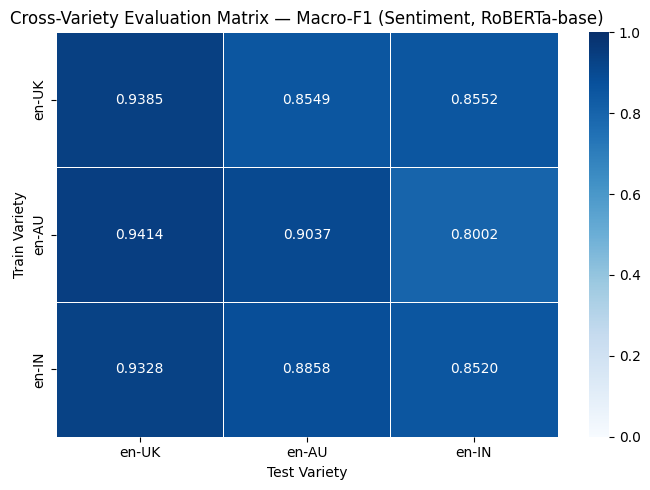

In [39]:
plt.figure(figsize=(7, 5))
sns.heatmap(
    matrix_df.astype(float),
    annot=True,
    fmt=".4f",
    cmap="Blues",
    vmin=0.0,
    vmax=1.0,
    linewidths=0.5,
    xticklabels=VARIETIES,
    yticklabels=VARIETIES
)
plt.title("Cross-Variety Evaluation Matrix — Macro-F1 (Sentiment, RoBERTa-base)")
plt.xlabel("Test Variety")
plt.ylabel("Train Variety")
plt.tight_layout()
plt.savefig("../results/tables/cross_variety_heatmap.png", dpi=150)
plt.show()

## Bar Chart: Transfer Performance by Test Variety

The grouped bar chart allows direct comparison of each trained model's performance across the three test varieties, making it easier to identify which training variety produces the most broadly transferable representations.

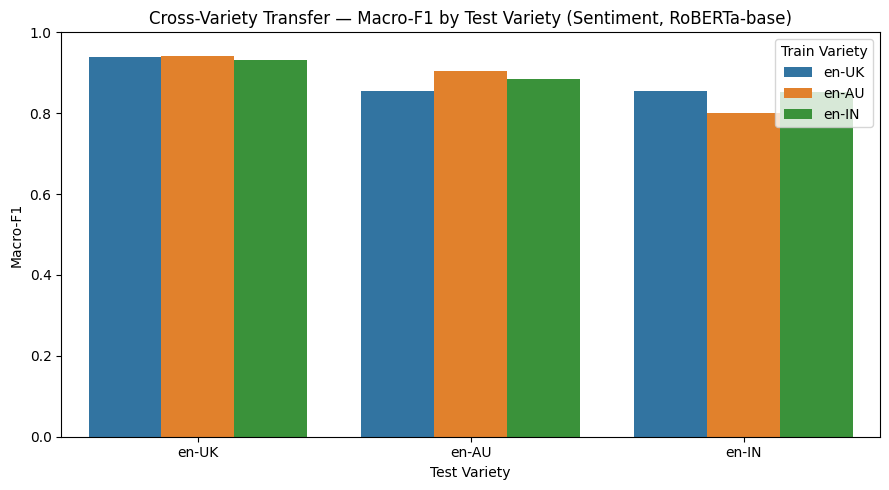

In [40]:
plot_df = results_df[["train_variety", "test_variety", "macro_f1"]].copy()

plt.figure(figsize=(9, 5))
sns.barplot(data=plot_df, x="test_variety", y="macro_f1", hue="train_variety")
plt.title("Cross-Variety Transfer — Macro-F1 by Test Variety (Sentiment, RoBERTa-base)")
plt.xlabel("Test Variety")
plt.ylabel("Macro-F1")
plt.ylim(0, 1)
plt.legend(title="Train Variety")
plt.tight_layout()
plt.savefig("../results/tables/cross_variety_barplot.png", dpi=150)
plt.show()

## Per-Class Classification Reports

Per-class precision, recall, and F1 are reported for every training–test variety combination. This confirms that models are not simply predicting the majority class, which would inflate accuracy while producing near-zero recall for the minority class.

In [41]:
for train_variety in VARIETIES:
    print(f"\n{'='*60}")
    print(f"Model trained on: {train_variety}")
    print(f"{'='*60}")

    trainer = trained_models[train_variety]

    for test_variety in VARIETIES:
        tokenized_test = prepare_dataset(test_by_variety[test_variety])
        preds  = trainer.predict(tokenized_test)
        y_pred = np.argmax(preds.predictions, axis=1)
        y_true = preds.label_ids

        print(f"\n  -> Tested on: {test_variety}")
        print(classification_report(
            y_true, y_pred,
            digits=4,
            zero_division=0,
            target_names=["Negative", "Positive"]
        ))


Model trained on: en-UK


Map: 100%|██████████| 700/700 [00:00<00:00, 24406.57 examples/s]



  -> Tested on: en-UK
              precision    recall  f1-score   support

    Negative     0.9304    0.9441    0.9372       340
    Positive     0.9465    0.9333    0.9399       360

    accuracy                         0.9386       700
   macro avg     0.9385    0.9387    0.9385       700
weighted avg     0.9387    0.9386    0.9386       700



Map: 100%|██████████| 667/667 [00:00<00:00, 24747.89 examples/s]



  -> Tested on: en-AU
              precision    recall  f1-score   support

    Negative     0.8073    0.9539    0.8745       347
    Positive     0.9377    0.7531    0.8354       320

    accuracy                         0.8576       667
   macro avg     0.8725    0.8535    0.8549       667
weighted avg     0.8699    0.8576    0.8557       667



...


  -> Tested on: en-UK
              precision    recall  f1-score   support

    Negative     0.8970    0.9735    0.9337       340
    Positive     0.9728    0.8944    0.9320       360

    accuracy                         0.9329       700
   macro avg     0.9349    0.9340    0.9328       700
weighted avg     0.9360    0.9329    0.9328       700



Map: 100%|██████████| 667/667 [00:00<00:00, 19751.35 examples/s]



  -> Tested on: en-AU
              precision    recall  f1-score   support

    Negative     0.8383    0.9712    0.8999       347
    Positive     0.9623    0.7969    0.8718       320

    accuracy                         0.8876       667
   macro avg     0.9003    0.8840    0.8858       667
weighted avg     0.8978    0.8876    0.8864       667



Map: 100%|██████████| 816/816 [00:00<00:00, 26443.27 examples/s]



  -> Tested on: en-IN
              precision    recall  f1-score   support

    Negative     0.8429    0.8860    0.8639       430
    Positive     0.8654    0.8161    0.8400       386

    accuracy                         0.8529       816
   macro avg     0.8542    0.8511    0.8520       816
weighted avg     0.8535    0.8529    0.8526       816



## Confusion Matrices: In-Variety vs. Cross-Variety

Confusion matrices are shown for two selected combinations to illustrate the qualitative difference between in-variety and cross-variety prediction. The in-variety matrix (trained on en-UK, tested on en-UK) is expected to show balanced predictions, while the cross-variety matrix (trained on en-UK, tested on en-IN) may reveal a systematic bias towards the majority class.

Map: 100%|██████████| 700/700 [00:00<00:00, 16564.62 examples/s]


Map: 100%|██████████| 816/816 [00:00<00:00, 22028.54 examples/s]


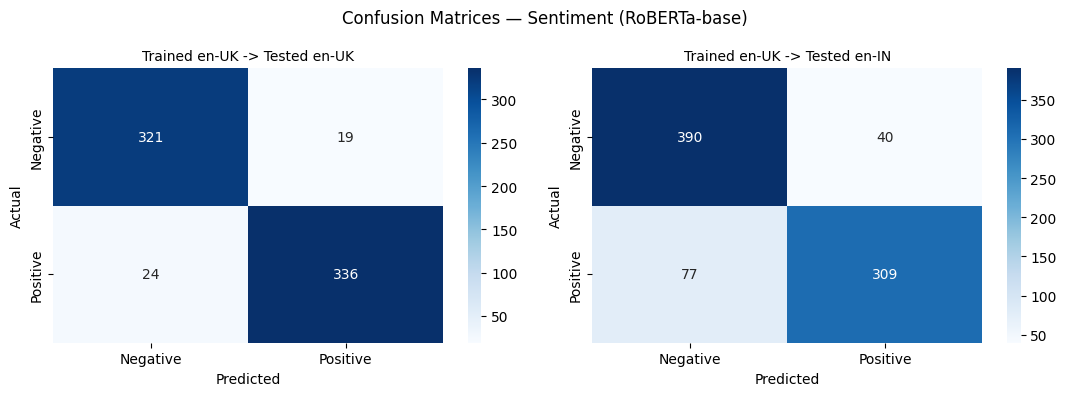

In [42]:
selected_pairs = [
    ("en-UK", "en-UK"),   # in-variety
    ("en-UK", "en-IN"),   # cross-variety
]

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

for ax, (train_variety, test_variety) in zip(axes, selected_pairs):
    trainer = trained_models[train_variety]
    tokenized_test = prepare_dataset(test_by_variety[test_variety])

    preds  = trainer.predict(tokenized_test)
    y_pred = np.argmax(preds.predictions, axis=1)
    y_true = preds.label_ids

    cm = confusion_matrix(y_true, y_pred)

    sns.heatmap(
        cm, annot=True, fmt="d", cmap="Blues", ax=ax,
        xticklabels=["Negative", "Positive"],
        yticklabels=["Negative", "Positive"]
    )
    ax.set_title(f"Trained {train_variety} -> Tested {test_variety}", fontsize=10)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

plt.suptitle("Confusion Matrices — Sentiment (RoBERTa-base)", fontsize=12)
plt.tight_layout()
plt.savefig("../results/tables/cross_variety_confusion_matrices.png", dpi=150)
plt.show()

## Interpretation of Cross-Variety Results

### In-Variety Performance (Diagonal)

Each model achieves its strongest performance when trained and tested on the same variety. In-variety Macro-F1 scores are consistently higher than off-diagonal scores, confirming that the linguistic characteristics of each variety are most effectively captured by a model trained on matching data.

### Inner-Circle Transfer: en-UK ↔ en-AU

The off-diagonal scores between en-UK and en-AU are comparatively high, indicating that British and Australian English share sufficient linguistic overlap for moderate cross-variety transfer. Both are inner-circle varieties with similar syntactic conventions, idiomatic expressions, and spelling norms, which reduces the variety gap between them.

### Outer-Circle Transfer: en-IN vs. en-UK / en-AU

The largest performance drops occur when a model trained on an inner-circle variety is tested on en-IN, and when a model trained on en-IN is tested on inner-circle varieties. Indian English is an outer-circle variety that exhibits distinct grammatical structures, code-mixing with Hindi, and culturally specific references. These features are poorly represented in inner-circle training data, leading to degraded generalisation.

### Comparison: Baseline vs Transformer Across Varieties

The results demonstrate that while RoBERTa's pre-trained representations provide some generic English understanding that supports partial transfer, the variety gap remains significant — particularly between inner- and outer-circle varieties. This finding directly motivates the use of variety-specific fine-tuning and confirms that treating English as a monolith leads to measurable performance degradation for non-standard varieties.